# DBSCAN Clustering

Attempts to cluster CGI sequences by species using DBSCAN, on two separate feature sets: 
1. core CGI physical features (GC content, length, obs/exp)
2. 3-mer composition (PCA-reduced)
Parameters (eps, min_samples) are tuned via the k-distance elbow method and evaluated by silhouette score.

**Input**: `dataset/processed/cpg_islands.csv`, `dataset/processed/3mer_features.csv`

**Output**: cluster labels (printed summary; not persisted to disk)

In [1]:
import pandas as pd
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
import plotly.express as px
from kneed import KneeLocator, find_shape
import numpy as np

In [2]:
islands = pd.read_csv('../dataset/processed/cpg_islands.csv')
kmer_features = pd.read_csv('../dataset/processed/3mer_features.csv')

In [3]:
kmer_features.head()

,id,AAA,AAT,AAG,AAC,ATA,ATT,ATG,ATC,AGA,...,CTG,CTC,CGA,CGT,CGG,CGC,CCA,CCT,CCG,CCC
0,AT1G14150,0.006098,0.018293,0.012195,0.024390,0.012195,0.012195,0.009146,0.030488,0.033537,...,0.021341,0.027439,0.015244,0.006098,0.021341,0.018293,0.024390,0.012195,0.024390,0.003049
1,AT1G14140,0.000000,0.018349,0.013761,0.013761,0.022936,0.004587,0.022936,0.027523,0.022936,...,0.018349,0.036697,0.013761,0.022936,0.013761,0.022936,0.009174,0.032110,0.032110,0.009174
2,AT1G64960,0.000000,0.004739,0.037915,0.000000,0.004739,0.009479,0.023697,0.009479,0.014218,...,0.018957,0.004739,0.014218,0.009479,0.014218,0.004739,0.009479,0.009479,0.014218,0.004739
3,AT1G08270,0.018779,0.018779,0.051643,0.014085,0.009390,0.014085,0.014085,0.018779,0.056338,...,0.014085,0.009390,0.023474,0.009390,0.037559,0.018779,0.014085,0.000000,0.014085,0.014085
4,AT1G08450,0.020690,0.018391,0.025287,0.022989,0.016092,0.013793,0.016092,0.011494,0.022989,...,0.009195,0.013793,0.027586,0.025287,0.022989,0.013793,0.020690,0.013793,0.013793,0.000000


In [4]:
# Standardize CGI features before DBSCAN, since it relies on Euclidean
# distance and 'length' (range: ~200-1000+) would otherwise dominate
# over 'gc-content'/'obs/exp' (range: ~0-2)

scaler = StandardScaler()
columns = ['gc-content',	'length',	'obs/exp']
cgi_features = islands[['id', 'gc-content',	'length',	'obs/exp']].copy()
cgi_features[columns] = scaler.fit_transform(cgi_features[columns])

In [5]:
cgi_features.head()

,id,gc-content,length,obs/exp
0,AT1G14150,-0.701699,-0.565879,-0.314289
1,AT1G14140,-0.528112,-0.955407,0.309705
2,AT1G64960,-0.387844,-0.980195,-1.342928
3,AT1G08270,-0.657284,-0.973113,1.480471
4,AT1G08450,-0.592958,-0.186975,1.231453


In [6]:
# Reduce 3-mer features to 11 principal components 
# (n=11 chosen in 03_feature_eda.ipynb via elbow method, reaching >=70% cumulative explained variance)
pca = PCA(n_components=11)
kmer_features_pca = pca.fit_transform(kmer_features.iloc[:,1:])

In [7]:
# min_samples candidates: multiples of feature dimensionality 
# min_samples >= dimensionality, often 2x as a starting point
min_samples_range_cgi = [6, 9, 12, 15]  # 2n, 3n, 4n, 5n where n=3 (gc-content, length, obs/exp)
min_samples_range_kmer = [10, 18, 27] 

In [8]:
def find_epsilon(features, min_samples_range):
    """
    For each candidate min_samples value, compute the k-th nearest neighbor distance for every point,
    sort them and find the knee(elbow) point in the resulting curve.
    This knee is used as the DBSCAN epsilon candidate for that min_samples value (standard heuristic: Ester et al., 1996).

    Args:
        features (array-like): feature matrix to cluster
        min_samples_range (list[int]): candidate min_samples values to test

    Returns:
        dict: {min_samples: elbow epsilon value}
    """
    eps_range = dict()

    # For candidates of minimum sampes value
    for min_sam in min_samples_range:
      # Distance to the min_sam-th nearest neighbor, for every point
      neighbors = NearestNeighbors(n_neighbors=min_sam)
      neighbors.fit(features)
      distances = neighbors.kneighbors(features)[0]
      kth_dist = []
      for distance in distances:
        kth_dist.append(max(distance))
      kth_dist.sort()

      # Visualize values
      fig = px.line(kth_dist, y=kth_dist, title=f"Distance to {min_sam}th nearest neighbors")
      fig.show()

      # Locate the elbow/knee point in the sorted distance curve
      x = np.arange(len(kth_dist))
      direc, curve = find_shape(x, kth_dist)
      kl = KneeLocator(x, kth_dist, curve=curve, direction=direc)
      eps_range[min_sam] = float(kl.knee_y)
      print(f"Optimal epsilon value for minimum samples = {min_sam}: {kl.knee_y}")

    return eps_range

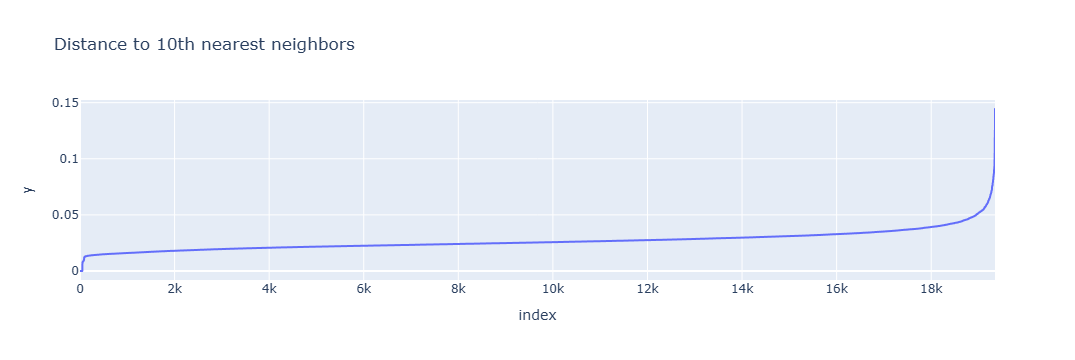

Optimal epsilon value for minimum samples = 10: 0.09072486685200039


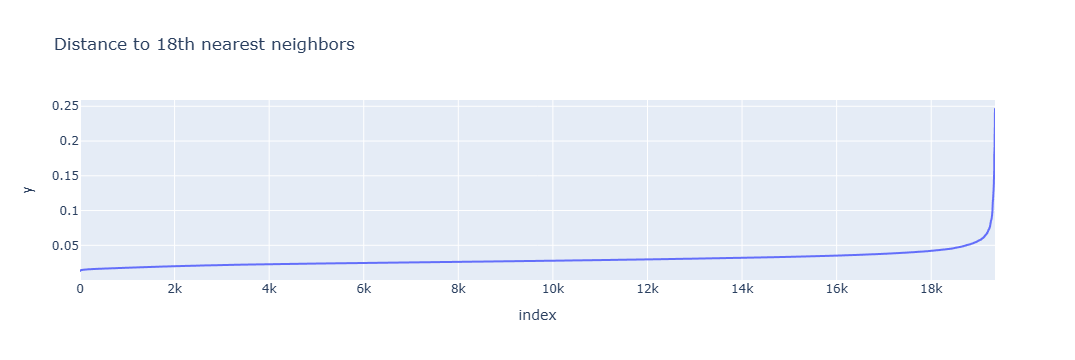

Optimal epsilon value for minimum samples = 18: 0.06992662252115107


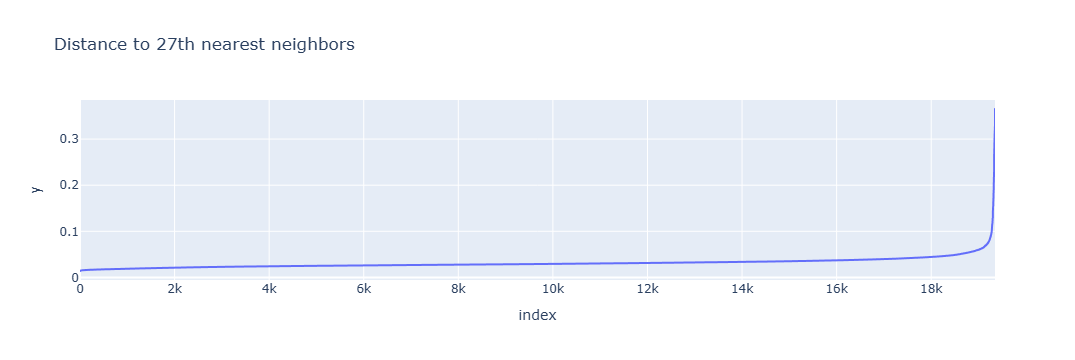

Optimal epsilon value for minimum samples = 27: 0.07937944620041709


In [11]:
kmer_eps = find_epsilon(kmer_features_pca, min_samples_range_kmer)

In [12]:
kmer_eps

{10: 0.09072486685200039, 18: 0.06992662252115107, 27: 0.07937944620041709}

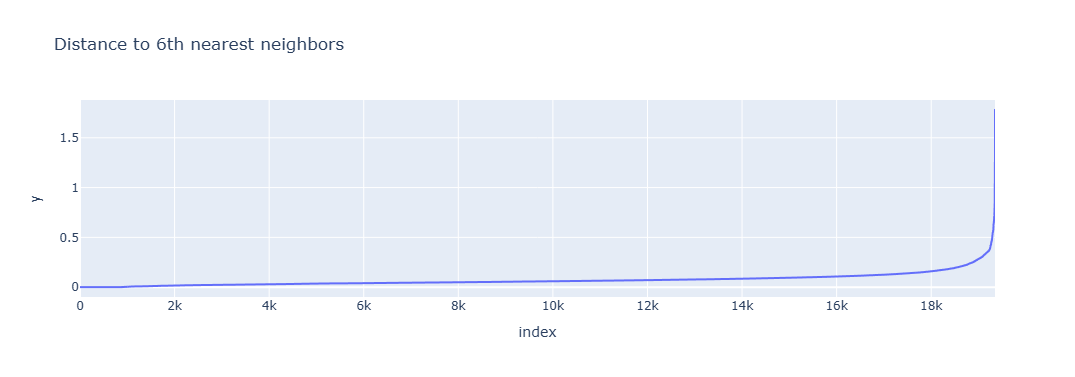

Optimal epsilon value for minimum samples = 6: 0.421383162969993


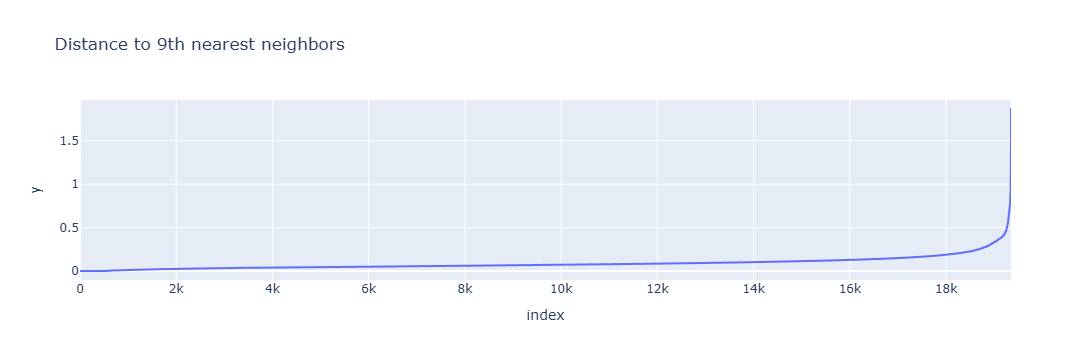

Optimal epsilon value for minimum samples = 9: 0.5017850934004877


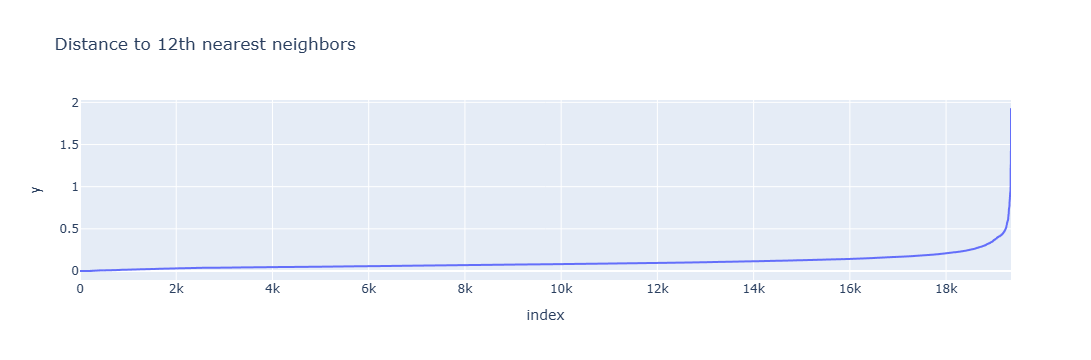

Optimal epsilon value for minimum samples = 12: 0.579778895766614


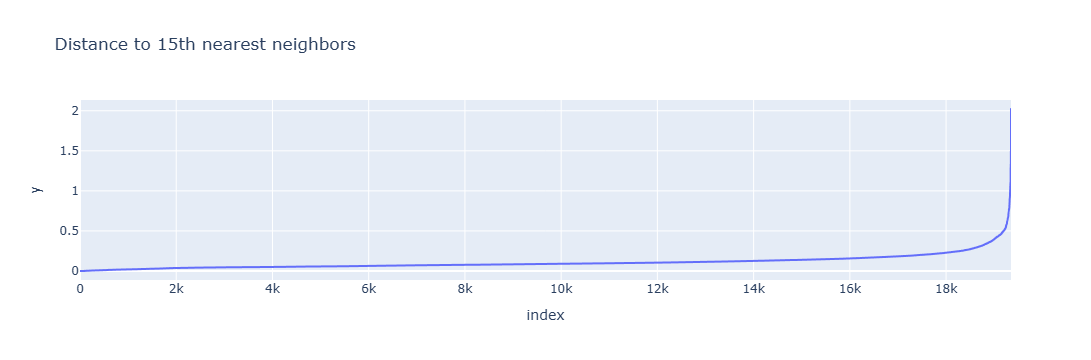

Optimal epsilon value for minimum samples = 15: 0.6565383973613051


In [13]:
cgi_eps = find_epsilon(cgi_features[columns], min_samples_range_cgi)

In [14]:
cgi_eps

{6: 0.421383162969993,
 9: 0.5017850934004877,
 12: 0.579778895766614,
 15: 0.6565383973613051}

In [16]:
def dbscan_scores(features, eps, min_sam_range):

    """
    Run DBSCAN for each (eps, min_samples) pair and compute the silhouette score, 
    to select the parameter combination that yields the most well-separated clusters.

    Args:
        features (array-like): feature matrix to cluster
        eps (dict): {min_samples: epsilon} from find_epsilon()
        min_sam_range (list[int]): candidate min_samples values

    Returns:
        dict: {min_samples: silhouette score}. 
            A score of -10 indicates silhouette_score could not be computed 
            (typically because DBSCAN produced only one cluster or all noise, which silhouette_score does not support).
    """
    silh_score = dict()
    for min_sam in min_sam_range:
        dbscan = DBSCAN(eps=eps[min_sam], min_samples=min_sam)
        try:
            silh_score[min_sam] = float(silhouette_score(features, dbscan.fit_predict(features)))
        except ValueError:
            # silhouette_score requires >=2 clusters; DBSCAN sometimes collapses everything into one cluster or all-noise
            silh_score[min_sam] = -10
    return silh_score

In [17]:
kmer_silhouette = dbscan_scores(kmer_features_pca, kmer_eps, min_samples_range_kmer)
kmer_silhouette

{10: 0.7542998886913093, 18: 0.786492700385844, 27: 0.7963795534814975}

In [18]:
cgi_silhouette = dbscan_scores(cgi_features[columns], cgi_eps, min_samples_range_cgi)
cgi_silhouette

{6: 0.33144759713262795,
 9: 0.3499054655127107,
 12: 0.3698676533196495,
 15: 0.38972196187124636}

In [19]:
# Select the (eps, min_samples) combination with the highest silhouette score
opt_min_sam_kmer = max(kmer_silhouette, key=kmer_silhouette.get)
opt_eps_kmer = kmer_eps[opt_min_sam_kmer]
opt_min_sam_cgi = max(cgi_silhouette, key=cgi_silhouette.get)
opt_eps_cgi = cgi_eps[opt_min_sam_cgi]

In [20]:
dbscan_kmer = DBSCAN(eps=opt_eps_kmer, min_samples=opt_min_sam_kmer).fit(kmer_features_pca)
labels_kmer = dbscan_kmer.labels_

# Shape of clusters
n_clusters_ = len(set(labels_kmer)) - (1 if -1 in labels_kmer else 0)
n_noise_ = list(labels_kmer).count(-1)
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 1
Estimated number of noise points: 63


In [21]:
dbscan_cgi = DBSCAN(eps=opt_eps_cgi, min_samples=opt_min_sam_cgi).fit(cgi_features[columns])
labels_cgi = dbscan_cgi.labels_

# Shape of clusters
n_clusters_ = len(set(labels_cgi)) - (1 if -1 in labels_cgi else 0)
n_noise_ = list(labels_cgi).count(-1)
print("Estimated number of clusters: %d" % n_clusters_)
print("Estimated number of noise points: %d" % n_noise_)

Estimated number of clusters: 1
Estimated number of noise points: 28
